## Week 3 Lab exercises

In this week we will explore the concept of object oreinted programming (OOP) with classes, and the numerical solution of simple non linear ordinary differential equations (ODEs). 

In [72]:

# first we import the libraries we need
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets


# The following lines makes the plots appear inline in the notebook matplotlib inline

%matplotlib inline

### ACTIVITY 1: 
I have written a class below for a Point object, which encapsulates the idea of a point and things we might want to do to it. 

Here you will write another class object for a Rectangle. You should consider and implement the following points:

1. What is the minimum information that is needed to fully describe a rectangle and its position in space? Assume for simplicity that its edges are aligned with the x and y axes.

2. Implement functions to:

    a. reflect the rectangle in the x and y axes
    
    b. grow the rectangle by an amount in x and y with the bottom left corner fixed
    
    c. grow the rectangle by an amount in x and y with the top right corner fixed
    
    d. plot the rectangle


3. What should be checked here? Can you add some asserts? Do you need to test the functions?

4. Would some of the methods needed make more sense to be implemented in the Points class instead of the Rectangle class? If so go ahead and edit it!

Point  P is [1. 2.]
Point  Q is [4.  7.5]
Point  R is [5.  9.5]
Distance is  6.264982043070834
42


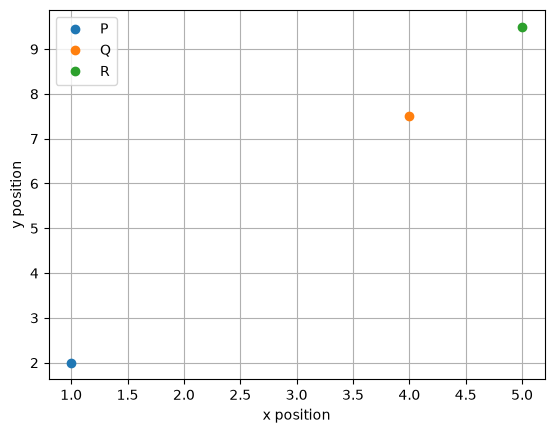

In [73]:
# Points class

class Point :
    """
    Represents a point in a 2D space
    
    attributes: [x, y], name
    
    """
    
    # constructor function
    # The double underscores indicate a private method or variable
    # not to be accessed outside the class (in principle)
    def __init__(self, coordinates = None , name = ""):
        if coordinates is None:
            coordinates = [0.0, 0.0]
        self.coordinates = np.array(coordinates, dtype=float)
        self.name = name
        self.__private_variable = 42
    @property
    def x(self):
        return self.coordinates[0]

    @property
    def y(self):
        return self.coordinates[1]
    
    def __add__(self, other) :
        new_point = Point(self.coordinates + other.coordinates)
        return new_point
    
    def print_point(self) :
        print("Point ", self.name, "is", self.coordinates)
        
    # Note that we don't use self here so don't need to pass it in
    # (This is a static function - it does not require an instance of the class)
    def calculate_distance_between_two_points(A, B) :
        return np.sqrt((A.x - B.x)**2.0 + (A.y - B.y)**2.0)
    
    def move_point(self,dx,dy) :
        self.coordinates = self.coordinates+ np.array([dx,dy])
        
    def plot_point(self, ax) :
        ax.plot(self.x, self.y, 'o', label=self.name)
        
    def update_name(self, new_name) :
        self.name = new_name
        
        
# Some examples of using the Points class
first_point = Point(coordinates = np.array([1,2]), name ="P")
first_point.print_point()

second_point = Point(np.array([3.0,5.5]),"Q")
second_point.move_point(1.0, 2.0)
second_point.print_point()

third_point = first_point + second_point
third_point.update_name("R")
third_point.print_point()

# Use the static function
distance = Point.calculate_distance_between_two_points(first_point,second_point)
print("Distance is ", distance)





plt.plot()
plt.grid()
plt.xlabel("x position")
plt.ylabel("y position")
ax = plt.gcf().gca()
first_point.plot_point(ax)
second_point.plot_point(ax)
third_point.plot_point(ax)
plt.legend()

# Try to access the private variable, even though you shouldn't
#print(first_point.__private_variable) # This won't work - try uncommenting it
print(first_point._Point__private_variable) # This will

# Can get info on the new class - uncomment to see this
# Point?

Rectangle  First Rectangle is [1 2] [6 5] [6 2] [1 5]
42


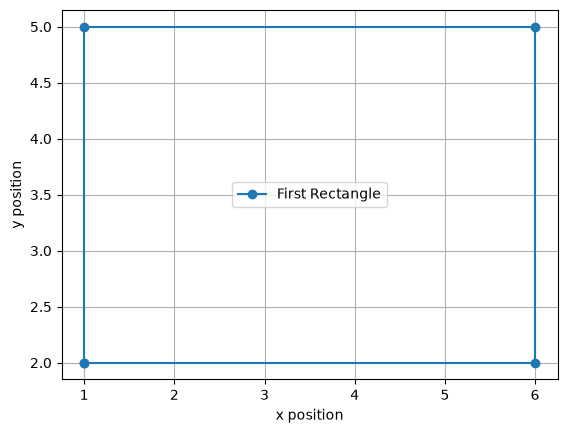

In [74]:
# Rectangle class
class Rectangle :
    """
    Represents a rectangle in a 2D space
    
    attributes: v_1, v_2, name
    
    """
    
    # constructor function
    # The double underscores indicate a private method or variable
    # not to be accessed outside the class (in principle)
    def __init__(self, v_1=np.array([0,0]), v_2=np.array([0,0]), name = ""):
        self.v_1 = v_1
        self.v_2 = v_2
        self.v_3 = np.array([v_2[0],v_1[1]])
        self.v_4 = np.array([v_1[0],v_2[1]])
        self.name = name
        self.__private_variable = 42
    def xreflect_rectangle(self) :
        new_rectangle = Rectangle(v_1 = np.array([self.v_1[0],float(-1*self.v_1[1])]), v_2 = np.array([self.v_2[0], float(-1*self.v_2[1])])) 
        return new_rectangle
    def yreflect_rectangle(self) :
        new_rectangle = Rectangle(v_1 = np.array([-self.v_1[0],self.v_1[1]]), v_2 = np.array([-self.v_2[0], self.v_2[1]])) 
        return new_rectangle
    def grow_v_2(self, delta) :
        new_rectangle = Rectangle(v_1 = self.v_1, v_2 = np.array([self.v_2[0]+delta, self.v_2[1]+delta]))
        return new_rectangle
    def grow_v_1(self,delta) :
        new_rectangle = Rectangle(v_1 = np.array([self.v_1[0]-delta, self.v_1[1]-delta]), v_2 = self.v_2 )
        return new_rectangle
    
    def print_rectangle(self) :
        print("Rectangle ", self.name, "is", self.v_1, self.v_2, self.v_3, self.v_4)
        

    def move_rectangle(self, dx, dy):
        shift = np.array([dx, dy], dtype=float)
        self.v_1 = self.v_1 + shift
        self.v_2 = self.v_2 + shift
        self.v_3 = self.v_3 + shift
        self.v_4 = self.v_4 + shift
        
    def plot_rectangle(self, ax) :
        vertices = np.array([self.v_1, self.v_3, self.v_2, self.v_4, self.v_1])
        ax.plot(vertices[:, 0], vertices[:, 1], 'o-', label=self.name)
        
    def update_name(self, new_name) :
        self.name = new_name
        
# Some examples of using the Rectangle class
first_rectangle = Rectangle(np.array([1,2]),np.array([6,5]) ,"First Rectangle")
first_rectangle.print_rectangle()

plt.plot()
plt.grid()
plt.xlabel("x position")
plt.ylabel("y position")
ax = plt.gcf().gca()
first_rectangle.plot_rectangle(ax)
plt.legend()

# Try to access the private variable, even though you shouldn't
#print(first_point.__private_variable) # This won't work - try uncommenting it
print(first_rectangle._Rectangle__private_variable)


In [75]:
from ipywidgets import interact, FloatSlider, Checkbox

base = Rectangle(np.array([1, 2]), np.array([6, 5]), "original")

def show(dx=0.0, dy=0.0, grow2=0.0, grow1=0.0, xreflect=False, yreflect=False):
    r = base.grow_v_2(grow2)
    r = r.grow_v_1(grow1)
    if xreflect:
        r = r.xreflect_rectangle()
    if yreflect:
        r = r.yreflect_rectangle()
    r.move_rectangle(dx, dy)
    r.update_name("transformed")

    fig, ax = plt.subplots(figsize=(6, 6))
    base.plot_rectangle(ax)
    r.plot_rectangle(ax)
    ax.set_xlim(-12, 12)
    ax.set_ylim(-12, 12)
    ax.set_aspect("equal")
    ax.grid(True)
    ax.axhline(0, color="k", lw=0.5)
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("x position")
    ax.set_ylabel("y position")
    ax.legend()
    plt.show()

slider = lambda lo, hi: FloatSlider(min=lo, max=hi, step=0.5, value=0.0, continuous_update=False)

interact(show,
         dx=slider(-10, 10), dy=slider(-10, 10),
         grow2=slider(-1.5, 6), grow1=slider(-1.5, 6),
         xreflect=Checkbox(value=False), yreflect=Checkbox(value=False));

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='dx', max=10.0, min=-10.0, s…

### ACTIVITY 2: 

Now create a Square class that has the same functionality as the rectangle class, but that in addition has the ability to calculate its own area. You are not allowed to modify the Rectangle class.

_HINT: Do you really need to write a whole new function from scratch? What about inheritance?_


Rectangle  Test Square is [1 1] [3. 3.] [3. 1.] [1. 3.]
Area of square is: 4.0


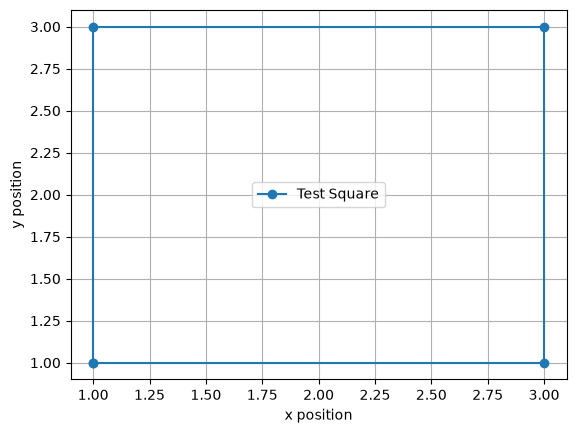

In [76]:
# Square class
class Square(Rectangle) :
    """
    Represents a square in a 2D space
    
    attributes: v_1, length, name
    
    """

    def __init__(self, v_1=np.array([0,0]), length = float(0), name = "") :
        self.v_1 = v_1
        self.v_2 = v_1 + np.array([length,length])
        self.v_3 = np.array([self.v_2[0],v_1[1]])
        self.v_4 = np.array([v_1[0],self.v_2[1]])
        self.length = length
        self.name = name
    def find_area_square(self) :
        return print("Area of square is:", float(self.length**2))

test_square = Square(np.array([1,1]), float(2), name ="Test Square")
test_square.print_rectangle()
test_square.find_area_square()
plt.plot()
plt.grid()
plt.xlabel("x position")
plt.ylabel("y position")
ax = plt.gcf().gca()
test_square.plot_rectangle(ax)
plt.legend()
# UPDATE ME

In [77]:
from ipywidgets import interact, FloatSlider, Checkbox

base = Square(np.array([1,1]), float(2), "Test Square")

def show(dx=0.0, dy=0.0, grow2=0.0, grow1=0.0, xreflect=False, yreflect=False):
    r = base.grow_v_2(grow2)
    r = r.grow_v_1(grow1)
    if xreflect:
        r = r.xreflect_rectangle()
    if yreflect:
        r = r.yreflect_rectangle()
    r.move_rectangle(dx, dy)
    r.update_name("transformed")

    fig, ax = plt.subplots(figsize=(6, 6))
    base.plot_rectangle(ax)
    r.plot_rectangle(ax)
    ax.set_xlim(-12, 12)
    ax.set_ylim(-12, 12)
    ax.set_aspect("equal")
    ax.grid(True)
    ax.axhline(0, color="k", lw=0.5)
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("x position")
    ax.set_ylabel("y position")
    ax.legend()
    plt.show()

slider = lambda lo, hi: FloatSlider(min=lo, max=hi, step=0.5, value=0.0, continuous_update=False)

interact(show,
         dx=slider(-10, 10), dy=slider(-10, 10),
         grow2=slider(-1.5, 6), grow1=slider(-1.5, 6),
         xreflect=Checkbox(value=False), yreflect=Checkbox(value=False));

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='dx', max=10.0, min=-10.0, s…

### ACTIVITY 3:

We now consider a simple system of coupled ODEs. The Lotka–Volterra equations describe predator–prey interactions between a prey population $x$ (for example, rabbits) and a predator population $y$ (for example, foxes). In the absence of predators, the prey population grows at a rate proportional to its size. In the absence of prey, the predator population declines at a rate proportional to its size. Predation occurs at a rate proportional to the product $xy$, reducing the prey population while supporting predator reproduction. The populations are therefore described by the following first-order, autonomous, nonlinear, coupled system of ordinary differential equations:

$\frac{dx}{dt} = ax - bxy$

$\frac{dy}{dt} = -cy + dxy$

Here, $a$ is the prey growth rate, $b$ measures predation, $c$ is the predator death rate, and $d$ measures how effectively consumed prey contributes to predator growth.

What parts or features of the differential equation tell us that it is:
1. First order: Highest order derivative is 1
2. Autonomous: The RHS does not depend on t
3. Non linear: Note every term involving the independent variables is linear.
4. Coupled: There are two differential equations which share the same variables, and can be combined into one equation with dy/dx

?

Answers: ... UPDATE ME!

### ACTIVITY 4:

The following code solves the Logistic Equation 

$\frac{dy}{dt} = y (1 - y)$

Using a simple explicit integration and the scipy function solve_ivp() which used Runge-Kutta 4th/5th order time integration. Copy it and update it to solve instead the Lotka-Volterra equations. 

Note the following:

1. Why do I substract delta_t when calculating the vector of t_solution points?
2. the solve_ivp method uses the labels t and y for the independent and dependent variables. The y value is assumed to be a vector, allowing you to solve for multiple dependent variables at once, e.g. you can make it np.array([x,y])

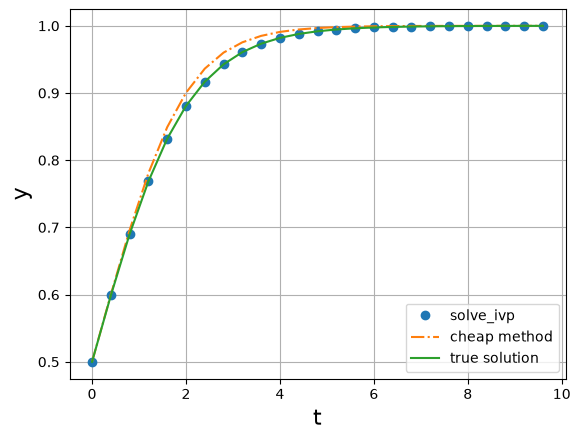

In [78]:
# Solve the 1d logistic equation from class
from scipy.integrate import solve_ivp

# Note that the function has to take t as the first argument and y as the second
def calculate_logistic_dydt(t, y):
    """Returns the gradient dx/dt for the logistic equation"""
    dydt = y*(1 - y)
    return dydt

max_time = 10.0
N_time_steps = 25
delta_t = max_time / N_time_steps
t_solution = np.linspace(0.0, max_time-delta_t, N_time_steps) # values of independent variable 
y0 = np.array([0.5]) # an initial condition, y(0) = y0, note it needs to be an array

solution = solve_ivp(calculate_logistic_dydt, [0,max_time], y0,
                        method='RK45', t_eval=t_solution)
 
plt.grid()
plt.xlabel("t", fontsize=16)
plt.ylabel("y", fontsize=16) 
plt.plot(solution.t, solution.y[0], 'o', label="solve_ivp")

# Now do it the "cheap" way 
# increase the number of steps to see how the solution changes
y_solution = np.zeros_like(t_solution)
y_solution[0] = y0[0]
for itime, time in enumerate(t_solution) :
    if itime > 0 :
        dydt = calculate_logistic_dydt(time, y_solution[itime-1])
        y_solution[itime] = y_solution[itime-1] + dydt * delta_t
    
plt.plot(t_solution, y_solution, '-.',label="cheap method")

# Now plot the true solution
A = 1.0/y0 - 1.0
y_true = 1.0 / (1.0 + A * np.exp(-t_solution))
plt.plot(t_solution, y_true, '-', label="true solution")
plt.legend(loc='best');

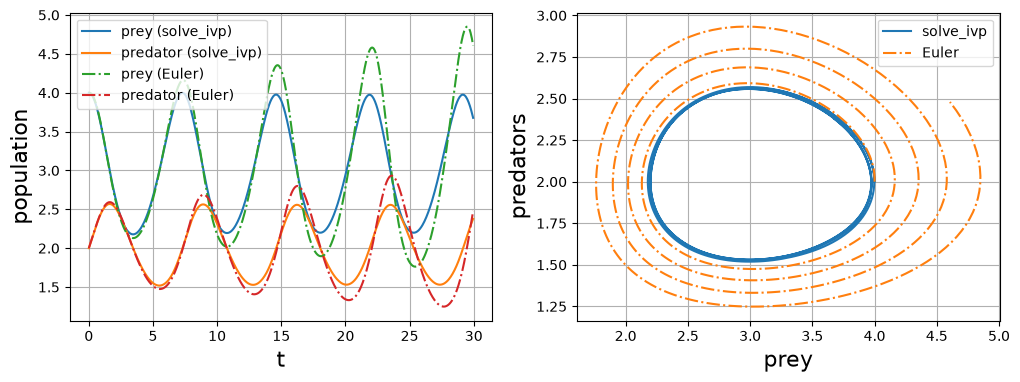

In [79]:
from scipy.integrate import solve_ivp

def calculate_lotka_volterra_dydt(t, state, growth_rate, predation,
                                  predator_death_rate, nutrition):
    """Returns [dx/dt, dy/dt] for prey x and predators y"""
    x, y = state
    dxdt = growth_rate * x - predation * x * y
    dydt = -predator_death_rate * y + nutrition * x * y
    return np.array([dxdt, dydt])

# Parameters
growth_rate = 1.0
predation = 0.5
predator_death_rate = 0.75
nutrition = 0.25
params = (growth_rate, predation, predator_death_rate, nutrition)

max_time = 30.0
N_time_steps = 600
delta_t = max_time / N_time_steps
t_solution = np.linspace(0.0, max_time - delta_t, N_time_steps)
state0 = np.array([4.0, 2.0])   # [prey, predators] at t = 0


solution = solve_ivp(calculate_lotka_volterra_dydt, [0, max_time], state0,
                     method='RK45', t_eval=t_solution, args=params)

# The "cheap" (Euler) method
state_euler = np.zeros((N_time_steps, 2))
state_euler[0] = state0
for itime, time in enumerate(t_solution):
    if itime > 0:
        dstate = calculate_lotka_volterra_dydt(time, state_euler[itime-1], *params)
        state_euler[itime] = state_euler[itime-1] + dstate * delta_t

#Code for plots done by claude ai
# Time series
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.grid()
ax1.set_xlabel("t", fontsize=16)
ax1.set_ylabel("population", fontsize=16)
ax1.plot(solution.t, solution.y[0], '-', label="prey (solve_ivp)")
ax1.plot(solution.t, solution.y[1], '-', label="predator (solve_ivp)")
ax1.plot(t_solution, state_euler[:, 0], '-.', label="prey (Euler)")
ax1.plot(t_solution, state_euler[:, 1], '-.', label="predator (Euler)")
ax1.legend(loc='best')

# Phase portrait
ax2.grid()
ax2.set_xlabel("prey", fontsize=16)
ax2.set_ylabel("predators", fontsize=16)
ax2.plot(solution.y[0], solution.y[1], '-', label="solve_ivp")
ax2.plot(state_euler[:, 0], state_euler[:, 1], '-.', label="Euler")
ax2.legend(loc='best');

### ACTIVITY 5:

Find the equilibrium value of rabbits and foxes such that you do not get oscillations.

_HINT: You can do this by trying different initial values of the rabbits and foxes, but it may help to also plot the solutions of x versus y for different values of the initial conditions and identify if there is a trend_

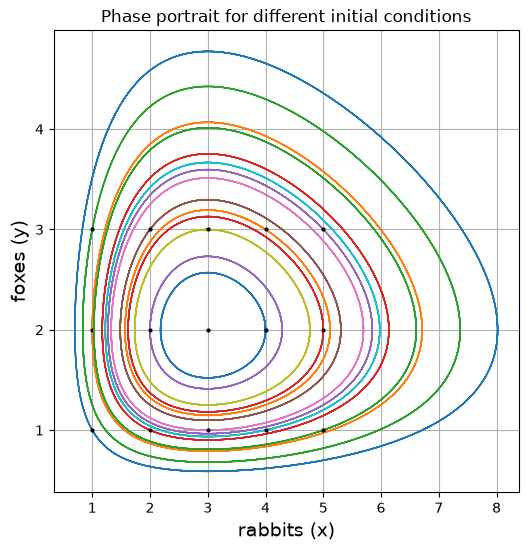

In [80]:
# Plot some solutions of x versus y
def solve_orbit(x0, y0, max_time=30.0, n=2000):
    t = np.linspace(0, max_time, n)
    sol = solve_ivp(calculate_lotka_volterra_dydt, [0, max_time], [x0, y0],
                    t_eval=t, args=params, rtol=1e-8, atol=1e-10)
    return sol.y[0], sol.y[1]

plt.figure(figsize=(6, 6))
for x0 in [1, 2, 3, 4, 5]:
    for y0 in [1, 2, 3]:
        x, y = solve_orbit(x0, y0)
        plt.plot(x, y, lw=1)
        plt.plot(x0, y0, 'k.', ms=4)   # starting point
plt.grid()
plt.xlabel("rabbits (x)", fontsize=14)
plt.ylabel("foxes (y)", fontsize=14)
plt.title("Phase portrait for different initial conditions");
# HINT: plt.plot(solution.y[0], solution.y[1], '--', label="x0, y0 = ??")

#Converges at (3,2)

### ACTIVITY 6:

If you double the resolution in the simple integrator, what happens to the error in the solution compared to solve_ivp? Why? How could you improve this behaviour?

300 0.1 2.768516789643196
600 0.05 0.9179431148308925
1200 0.025 0.37357444435599607
2400 0.0125 0.16987175898260176
measured order: 1.3376795006935762


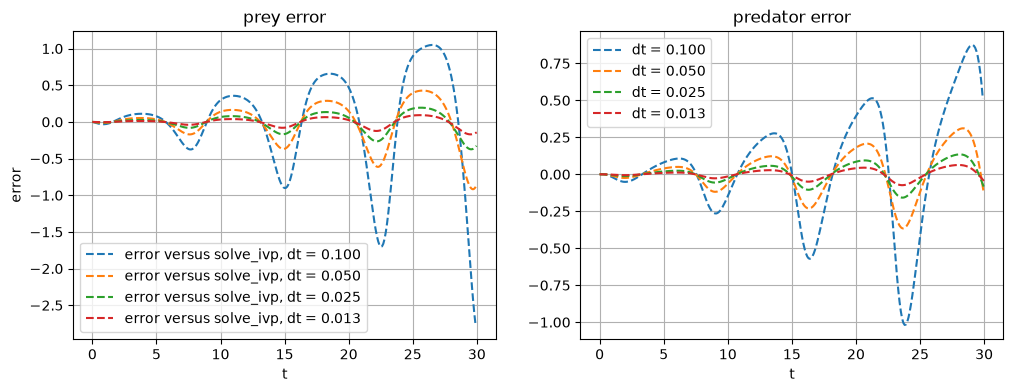

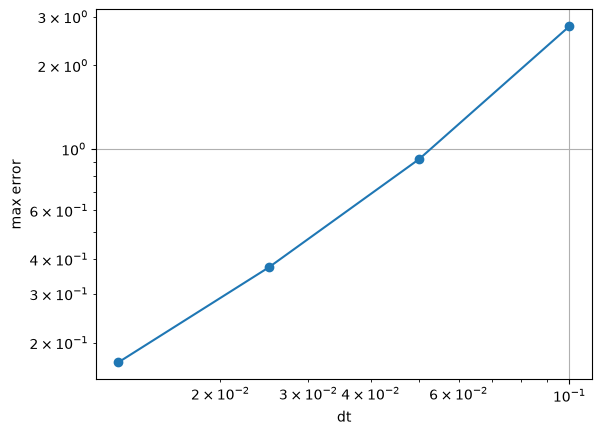

In [81]:
# Compare the errors here
def euler_lv(N, max_time=30.0):
    dt = max_time / N
    t = np.linspace(0.0, max_time - dt, N)
    s = np.zeros((N, 2))
    s[0] = state0
    for i in range(1, N):
        s[i] = s[i-1] + dt * calculate_lotka_volterra_dydt(t[i-1], s[i-1], *params)
    return t, s, dt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
dts, max_errs = [], []
for N in [300, 600, 1200, 2400]:
    t_solution, y_solution, dt = euler_lv(N)
    solution = solve_ivp(calculate_lotka_volterra_dydt, [0, 30.0], state0,
                         method='RK45', t_eval=t_solution, args=params,
                         rtol=1e-10, atol=1e-12)
    ax1.plot(solution.t, solution.y[0] - y_solution[:, 0], '--',
             label=f"error versus solve_ivp, dt = {dt:.3f}")
    ax2.plot(solution.t, solution.y[1] - y_solution[:, 1], '--',
             label=f"dt = {dt:.3f}")
    dts.append(dt)
    max_errs.append(np.max(np.abs(solution.y - y_solution.T)))
    print(N, dt, max_errs[-1])

ax1.set_title("prey error"); ax2.set_title("predator error")
for ax in (ax1, ax2):
    ax.grid(); ax.set_xlabel("t"); ax.legend()
ax1.set_ylabel("error");

# Order of convergence: slope of log(error) vs log(dt)
plt.figure()
plt.loglog(dts, max_errs, 'o-')
plt.grid(); plt.xlabel("dt"); plt.ylabel("max error")
print("measured order:", np.polyfit(np.log(dts), np.log(max_errs), 1)[0])

# HINT: plt.plot(solution.t, solution.y[0] - y_solution, '--', label="error versus solve_ivp, dt = ??")

### ACTIVITY 7:

The predator - prey equations have been cast above in a _functional coding_ style. Can you imagine a way to cast them in a more OOP way?

_HINT: There are several ways this could be done, but consider writing an Ecosystem class - what would be the attributes and methods that would live in such a class?_

OPTIONAL: Implement it!

A: UPDATE ME!

In [82]:
# Implementation of the Ecosystem class (OPTIONAL)
